<a href="https://colab.research.google.com/github/Roun-02/DSMBC-Online-Shoppers-Intention/blob/main/DSMBC_Online_Shoppers_Intention_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# 1. Understand Problem & Define Objective

## 1.1 Latar belakang
Platform e-commerce ingin tahu apakah sebuah sesi kunjungan akan berakhir dengan transaksi. Mayoritas sesi tidak menghasilkan pembelian, sehingga perilaku browsing (halaman yang dibuka, durasi, *bounce rate*, *exit rate*) dapat dipakai sebagai petunjuk niat membeli.

## 1.2 Problem statement
> Pola perilaku kunjungan apa (halaman yang dibuka, durasi, *bounce rate*, *exit rate*), waktu kunjungan, dan karakteristik pengunjung yang berkaitan dengan terjadinya transaksi (`Revenue` = True/False)?

**Jenis analisis:** notebook ini adalah *Exploratory Data Analysis* (EDA). Target (`Revenue`) bernilai True/False dengan jumlah kelas yang tidak seimbang, sehingga hasil EDA ini dapat menjadi dasar untuk membuat model klasifikasi di tahap berikutnya. Unit analisis adalah **satu sesi**, bukan satu pengguna, karena dataset tidak punya identitas pengguna.

## 1.3 Tujuan

| Level | Tujuan |
|---|---|
| **Bisnis** | (a) Mengetahui sesi seperti apa yang cenderung berakhir transaksi, sehingga peluang menaikkan *conversion rate* lebih jelas. (b) Membantu menentukan kapan dan kepada siapa marketing dan *retargeting* sebaiknya difokuskan. (c) Memberi bahan perbaikan desain situs dari perilaku yang berkaitan dengan pembelian. |
| **Eksplorasi (notebook ini)** | Memahami data, menemukan fitur yang paling berkaitan dengan transaksi, dan mencatat masalah data (distribusi miring, outlier, fitur yang berkorelasi tinggi, duplikat) sebelum masuk ke tahap modeling. |
| **Lanjutan (di luar notebook ini)** | Membuat model yang dapat memperkirakan sesi yang akan berakhir transaksi. |

## 1.4 Mengapa kelas yang tidak seimbang perlu diperhatikan
Dengan ±15% sesi berakhir pembelian, menebak "tidak beli" untuk semua sesi sudah benar ±85%, tetapi tidak berguna secara bisnis karena tidak ada pembeli yang berhasil ditemukan. Karena itu proporsi kelas `Revenue` dicek lebih dulu pada bagian Analisis Target. Pada tahap modeling nanti, *accuracy* saja tidak cukup, sehingga perlu juga dilihat *precision*, *recall*, dan F1 untuk kelas pembeli.

## 1.5 Cara membaca hasil EDA
- *Conversion rate* antar kategori dibaca bersama jumlah sesinya. Kategori dengan sesi sedikit (misalnya Februari) angkanya mudah berubah.
- Korelasi dan perbedaan yang terlihat menunjukkan **keterkaitan**, bukan bukti sebab-akibat.
- Hasil EDA hanya menggambarkan data ini (12.330 sesi) dan belum membuktikan kinerja model apa pun.

## 1.6 Important Question
1. Berapa conversion rate keseluruhan dan seberapa tidak seimbang datanya?
2. Fitur perilaku apa yang paling kuat berkaitan dengan transaksi?
3. Apakah conversion rate berbeda antara returning dan new visitor, serta antar bulan?
4. Fitur mana yang distribusinya miring dan berkorelasi tinggi, dan apa dampaknya untuk tahap modeling?

Pertanyaan 1–4 dijawab di notebook ini (rangkumannya ada di bagian akhir). Pemilihan model dan analisis sesi yang sering salah diprediksi akan dibahas pada tahap modeling, di luar notebook ini.

## 1.7 Hipotesis awal yang akan diuji di EDA

| # | Hipotesis |
|---|---|
| H1 | `PageValues` tinggi berkaitan kuat dengan pembelian. |
| H2 | `ExitRates` dan `BounceRates` rendah berkaitan dengan pembelian. |
| H3 | Sesi pembeli membuka lebih banyak halaman produk dan durasinya lebih panjang. |
| H4 | Returning visitor dan new visitor punya conversion rate berbeda. |
| H5 | Conversion rate bervariasi antar bulan (musiman). |
| H6 | Kode `OperatingSystems`, `Browser`, `Region`, `TrafficType` bersifat nominal dan tidak boleh dibaca sebagai urutan. |
| H7 | `BounceRates` dan `ExitRates` berkorelasi tinggi (risiko multikolinearitas bagi model linear). |

## 1.8 Asumsi dan risiko yang perlu dikawal sejak awal
- **Potensi kebocoran informasi (*leakage*) pada `PageValues`:** nilainya adalah rata-rata nilai halaman yang dikunjungi sebelum transaksi, sehingga bisa jadi baru diketahui mendekati akhir sesi. Jika nanti dipakai untuk prediksi *real-time*, fitur ini mungkin belum tersedia saat keputusan dibuat. EDA ini hanya mencatat seberapa kuat kaitannya dengan transaksi.
- **Cakupan waktu terbatas:** data hanya mencakup 10 bulan (Januari dan April tidak ada), jadi kesimpulan musiman terbatas.
- **Tidak ada identitas pengguna:** satu pengguna bisa muncul di banyak sesi. Pada tahap modeling, pembagian data secara acak berisiko memasukkan perilaku yang mirip ke data latih dan data uji.
- **Sesi yang sama persis (duplikat):** ada 125 baris duplikat, penanganannya dicatat pada bagian Mengecek Duplicate Value.

# **INISIALISASI DATASET**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

url = "https://raw.githubusercontent.com/Roun-02/DSMBC-Online-Shoppers-Intention/refs/heads/main/online_shoppers_intention.csv"
df = pd.read_csv(url)

# Konfigurasi tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.figsize'] = (8, 5)

RANDOM_STATE = 42

# **OVERVIEW DATA**

In [2]:
df.shape

(12330, 18)

Dataset memiliki 12.330 baris data dan 18 kolom. Dataset ini memiliki target kolom yaitu kolom **Revenue**


In [3]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Dataset memiliki beberapa kolom yang dapat didefinisikan:
| **Kolom** | **Keterangan Singkat** |
|-----------|-------------------------|
| **Administrative** | Jumlah halaman administrasi yang dikunjungi pengguna. |
| **Administrative_Duration** | Total waktu yang dihabiskan pada halaman administrasi (detik). |
| **Informational** | Jumlah halaman informasi yang dikunjungi. |
| **Informational_Duration** | Total waktu pada halaman informasi (detik). |
| **ProductRelated** | Jumlah halaman produk yang dikunjungi. |
| **ProductRelated_Duration** | Total waktu pada halaman produk (detik). |
| **BounceRates** | Rata-rata *bounce rate* (persentase pengunjung yang langsung keluar setelah membuka satu halaman) dari halaman-halaman yang dibuka dalam satu sesi. |
| **ExitRates** | Rata-rata *exit rate* (persentase kunjungan sebuah halaman yang menjadi halaman terakhir sesi) dari halaman-halaman yang dibuka dalam satu sesi. |
| **PageValues** | Rata-rata nilai halaman yang dibuka sebelum terjadi transaksi (nilai halaman diukur dari kontribusinya terhadap transaksi). |
| **SpecialDay** | Kedekatan waktu kunjungan dengan hari spesial atau hari promosi (nilai 0–1). Pada data ini nilainya lebih dari 0 hanya pada Februari dan Mei. |
| **Month** | Bulan saat sesi kunjungan terjadi. |
| **OperatingSystems** | Sistem operasi yang digunakan pengunjung. |
| **Browser** | Browser yang digunakan pengunjung. |
| **Region** | Wilayah asal pengunjung. |
| **TrafficType** | Sumber atau jenis lalu lintas pengunjung ke situs. |
| **VisitorType** | Tipe pengunjung (misalnya Returning Visitor atau New Visitor). |
| **Weekend** | Menunjukkan apakah kunjungan terjadi pada akhir pekan (True/False). |
| **Revenue** | Target data, menunjukkan apakah sesi menghasilkan transaksi (True/False). |

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

Dataset terdiri dari **18 kolom**, yang terdiri atas **10 fitur bertipe numerik, 7 fitur bertipe kategorikal, dan 1 kolom target (Revenue)**.

Fitur numerik meliputi:
1. Administrative
2. Administrative_Duration
3. Informational
4. Informational_Duration
5. ProductRelated
6. ProductRelated_Duration
7. BounceRates
8. ExitRates
9. PageValues
10. SpecialDay

Fitur kategorikal meliputi:
1. Month
2. OperatingSystems
3. Browser
4. Region
5. TrafficType
6. VisitorType
7. Weekend

Berdasarkan hasil pemeriksaan, dataset tidak memiliki missing value, yang ditunjukkan oleh seluruh kolom memiliki jumlah data yang sama, yaitu 12.330 baris.

# **STATISTIK DESKRIPTIF**

In [5]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


Sebagian besar fitur numerik memiliki nilai minimum 0, yang menunjukkan banyak sesi tidak mengakses jenis halaman tertentu, terutama pada Administrative, Informational, dan PageValues. Selain itu, beberapa fitur seperti ProductRelated_Duration dan PageValues memiliki nilai maksimum yang jauh lebih besar dibandingkan rata-ratanya, sehingga terdapat kemungkinan adanya skewed dan kemungkinan terdapat outlier.

In [6]:
df.describe(include='object')

,Month,VisitorType
count,12330,12330
unique,10,3
top,May,Returning_Visitor
freq,3364,10551


Terdapat 10 kategori bulan (Month) dan 3 jenis pengunjung (VisitorType). Bulan May merupakan bulan dengan jumlah sesi terbanyak (3.364 sesi), sedangkan Returning_Visitor merupakan tipe pengunjung yang paling dominan dengan 10.551 sesi dari total 12.330 sesi.

Bulan Januari dan April tidak ada dalam data, sehingga data hanya mencakup 10 dari 12 bulan.

# **MENGECEK MISSING VALUE**

In [7]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


Tidak ditemukan missing value sehingga data dapat langsung dianalisis lebih lanjut.

# **MENGECEK DUPLICATE VALUE**

In [8]:
df.duplicated().sum()

np.int64(125)

In [9]:
dup_mask = df.duplicated(keep=False)
print('Baris duplikat (salinan ekstra) :', df.duplicated().sum())
print('Baris yang terlibat duplikasi   :', dup_mask.sum())
print('Persentase Revenue=True di baris tersebut:', round(df.loc[dup_mask, 'Revenue'].mean()*100, 2), '%')

df_tanpa_duplikat = df.drop_duplicates()
print(f"Conversion rate: {df['Revenue'].mean()*100:.2f}% (data asli) -> {df_tanpa_duplikat['Revenue'].mean()*100:.2f}% (tanpa duplikat)")

Baris duplikat (salinan ekstra) : 125
Baris yang terlibat duplikasi   : 201
Persentase Revenue=True di baris tersebut: 0.0 %
Conversion rate: 15.47% (data asli) -> 15.63% (tanpa duplikat)


Terdapat 125 baris yang terdeteksi sebagai data duplikat.

Setelah dicek, semua baris yang terlibat duplikasi berstatus `Revenue = False` (tidak ada pembeli). Ini wajar karena sesi yang sangat singkat, misalnya langsung keluar setelah membuka satu halaman, bisa saja tercatat sama persis. Pengaruhnya ke hasil juga kecil: conversion rate hanya bergeser dari 15,47% menjadi 15,63% jika duplikat dibuang.

**Keputusan:** duplikat **tidak dibuang pada EDA ini** supaya angka tetap utuh, dan dicatat untuk dipertimbangkan pada tahap modeling.

# **MEMISAHKAN KOLOM NUMERIK DAN KATEGORIKAL**

In [10]:
# Fitur numerik sebenarnya (besaran, durasi, rasio)
num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates',
            'PageValues', 'SpecialDay']

# Fitur kategorikal. OperatingSystems, Browser, Region, TrafficType berbentuk angka, tetapi itu hanya KODE
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

target = 'Revenue'

# pastikan tidak ada kolom yang terlewat
assert sorted(num_cols + cat_cols + [target]) == sorted(df.columns)

print(num_cols)
print(cat_cols)
print(target)

['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Revenue


**Kolom numerik** terdapat: 'Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'

**Kolom kategorikal** terdapat: 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend'

**Kolom target**: 'Revenue'

# **ANALISIS TARGET**

In [11]:
df['Revenue'].value_counts()

,count
Revenue,
False,10422
True,1908


Pada kolom Revenue yang merupakan kolom dengan tipe kategorikal dan memiliki tipe data boolean, terdapat **10422** data bernilai "False" dan **1908** data bernilai "True"

In [12]:
df['Revenue'].value_counts(normalize=True)*100

,proportion
Revenue,
False,84.525547
True,15.474453


<Axes: xlabel='Revenue', ylabel='count'>

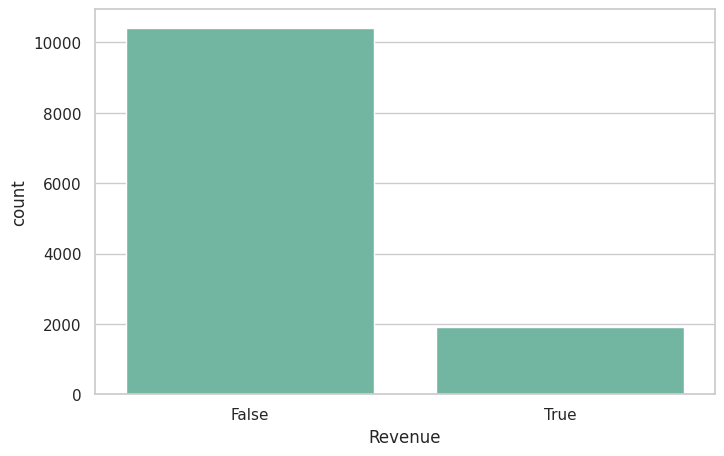

In [13]:
sns.countplot(x='Revenue', data=df)

Dalam bentuk persentase, terlihat nilai "False" memiliki nilai sebesar 84.5% berbanding dengan nilai "True" yang hanya memiliki nilai sebesar 15.5%. Ini menandakan pada dataset terdapat class imbalance.

# **ANALISIS DISTRIBUSI FITUR NUMERIK**

array([[<Axes: title={'center': 'Administrative'}>,
        <Axes: title={'center': 'Administrative_Duration'}>,
        <Axes: title={'center': 'Informational'}>,
        <Axes: title={'center': 'Informational_Duration'}>],
       [<Axes: title={'center': 'ProductRelated'}>,
        <Axes: title={'center': 'ProductRelated_Duration'}>,
        <Axes: title={'center': 'BounceRates'}>,
        <Axes: title={'center': 'ExitRates'}>],
       [<Axes: title={'center': 'PageValues'}>,
        <Axes: title={'center': 'SpecialDay'}>,
        <Axes: title={'center': 'OperatingSystems'}>,
        <Axes: title={'center': 'Browser'}>],
       [<Axes: title={'center': 'Region'}>,
        <Axes: title={'center': 'TrafficType'}>, <Axes: >, <Axes: >]],
      dtype=object)

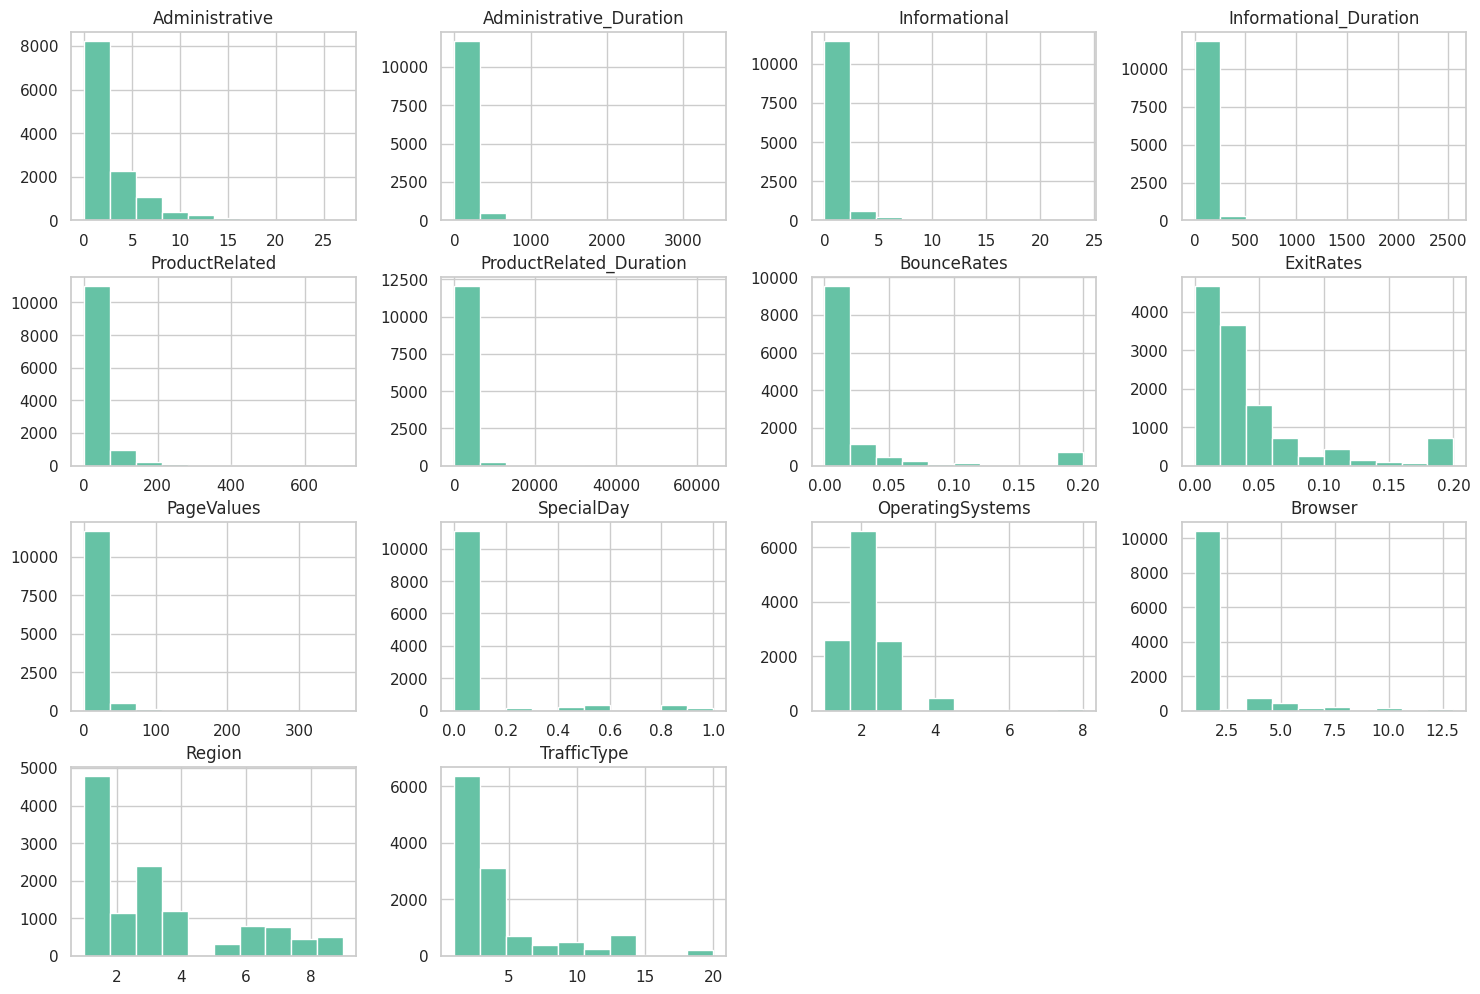

In [14]:
df.hist(figsize=(18,12))

Berdasarkan histogram, sebagian besar fitur memiliki distribusi yang miring ke kanan (right-skewed). Hal ini berarti sebagian besar data memiliki nilai yang kecil atau bahkan 0, sedangkan hanya sedikit data yang memiliki nilai sangat besar. Pola ini terlihat pada fitur seperti Administrative, Informational, ProductRelated, ProductRelated_Duration, dan PageValues.

Selain itu, BounceRates dan ExitRates juga didominasi oleh nilai yang rendah, sehingga menunjukkan bahwa sebagian besar sesi memiliki tingkat bounce dan exit yang kecil. Sementara itu, OperatingSystems, Browser, Region, dan TrafficType merupakan fitur kategorikal yang direpresentasikan dengan angka, sehingga bentuk histogramnya menunjukkan frekuensi setiap kategori, bukan distribusi nilai numerik.

# **OUTLIER**

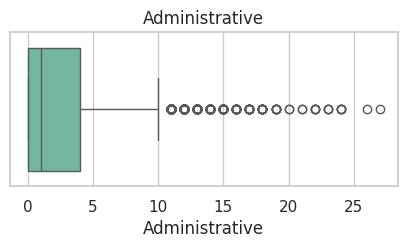

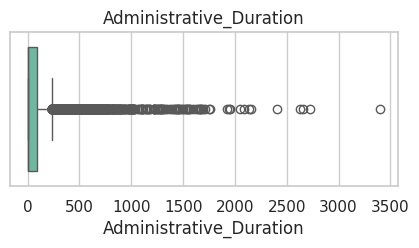

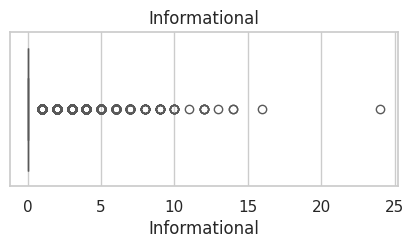

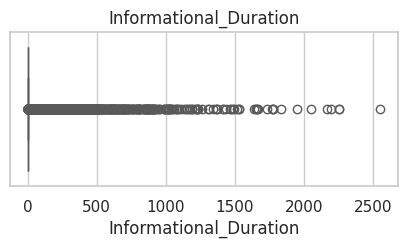

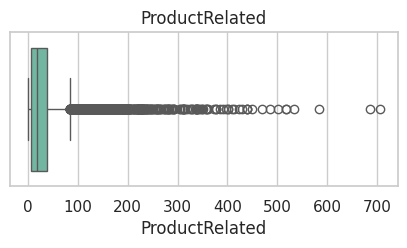

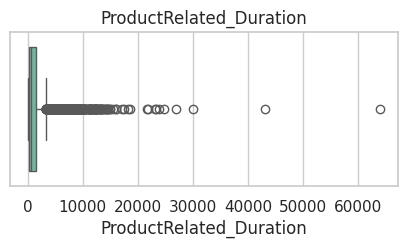

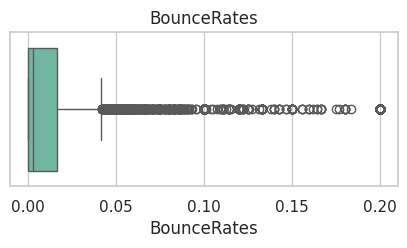

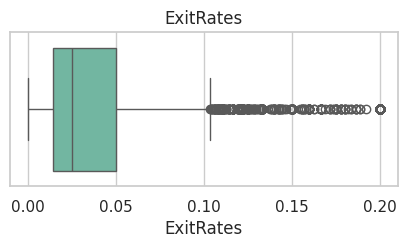

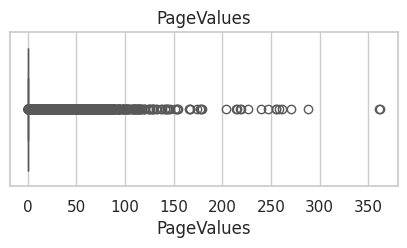

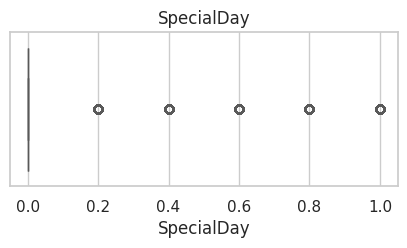

In [15]:
for col in num_cols:
    plt.figure(figsize=(5,2))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

Berdasarkan boxplot, hampir semua fitur numerik memiliki outlier, yaitu data yang berada jauh di luar rentang sebagian besar data. Hal ini terlihat dari banyaknya titik yang berada di luar garis whisker pada fitur seperti Administrative, Administrative_Duration, Informational, ProductRelated, ProductRelated_Duration, BounceRates, ExitRates, dan PageValues. Keberadaan outlier ini sejalan dengan hasil histogram sebelumnya yang menunjukkan distribusi data miring ke kanan (right-skewed).

Boxplot hanya dibuat untuk 10 fitur numerik. OperatingSystems, Browser, Region, dan TrafficType tidak dibuatkan boxplot karena berupa kode kategori, sehingga titik di luar whisker pada fitur tersebut tidak dapat dianggap outlier yang sebenarnya. Keempatnya diperlakukan sebagai data kategorikal pada tahap preprocessing.

In [16]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    rows.append((col, q1, q3, n_out, round(n_out/len(df)*100, 1), df[col].max()))
pd.DataFrame(rows, columns=['fitur', 'Q1', 'Q3', 'jumlah_outlier', 'persen', 'nilai_maks'])

,fitur,Q1,Q3,jumlah_outlier,persen,nilai_maks
0,Administrative,0.000000,4.000000,404,3.3,27.000000
1,Administrative_Duration,0.000000,93.256250,1172,9.5,3398.750000
2,Informational,0.000000,0.000000,2631,21.3,24.000000
3,Informational_Duration,0.000000,0.000000,2405,19.5,2549.375000
4,ProductRelated,7.000000,38.000000,987,8.0,705.000000
5,ProductRelated_Duration,184.137500,1464.157214,961,7.8,63973.522230
6,BounceRates,0.000000,0.016813,1551,12.6,0.200000
7,ExitRates,0.014286,0.050000,1099,8.9,0.200000
8,PageValues,0.000000,0.000000,2730,22.1,361.763742
9,SpecialDay,0.000000,0.000000,1251,10.1,1.000000


Pada PageValues, sekitar 78% nilainya adalah 0 (Q1 dan Q3 sama-sama 0), sehingga semua nilai di atas 0 ikut terhitung sebagai outlier (22,1% sesi). Artinya angka outlier pada fitur ini tidak berarti datanya salah.

**Keputusan:** outlier tidak dibuang pada EDA ini. Nilai besar tersebut adalah perilaku yang nyata (misalnya sesi yang sangat panjang) dan banyak terdapat pada sesi pembeli. Pada tahap modeling, outlier bisa ditangani dengan transformasi (misalnya log) atau dengan model yang tidak terlalu terpengaruh nilai ekstrem.

# **HEATMAP**

<Axes: >

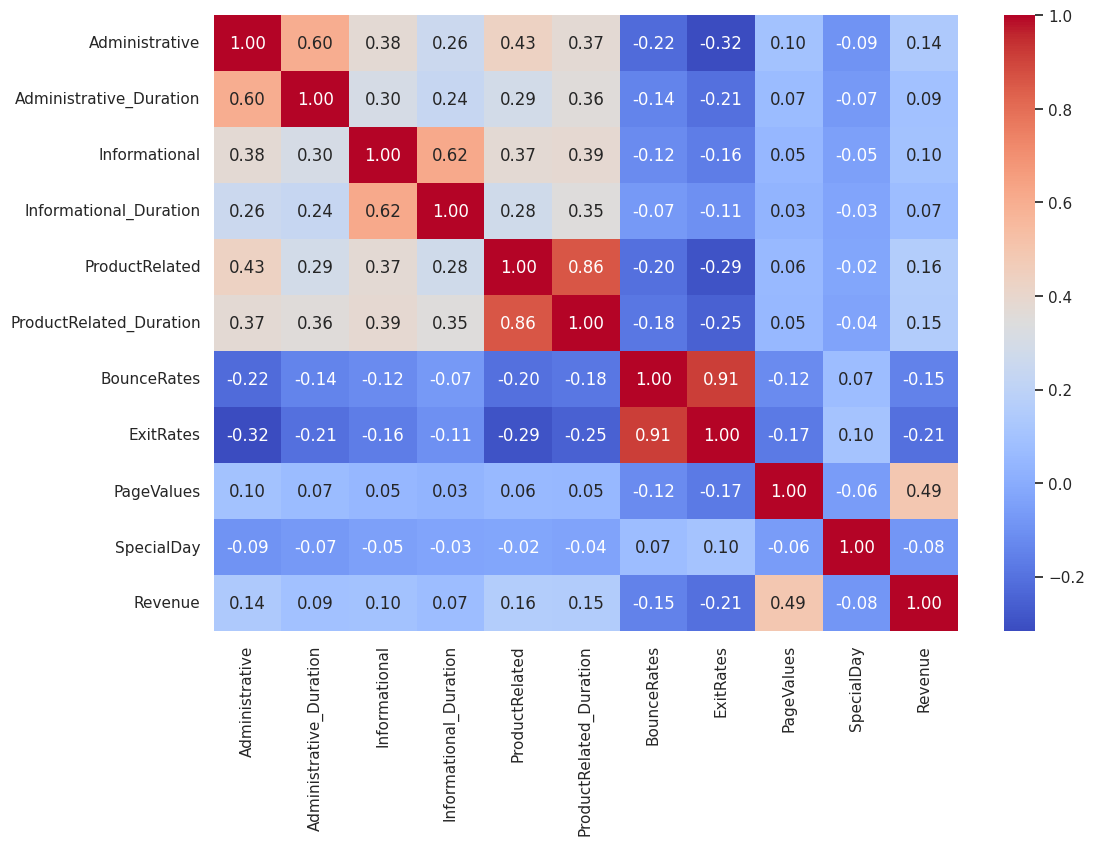

In [17]:
corr = df[num_cols + ['Revenue']].corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')

Heatmap dibuat dari 10 fitur numerik dan Revenue. OperatingSystems, Browser, Region, dan TrafficType tidak dimasukkan karena berupa kode kategori, sehingga korelasinya tidak bermakna.

Berdasarkan heatmap korelasi, sebagian besar pasangan fitur memiliki korelasi rendah sampai sedang. Namun, terdapat beberapa pasangan fitur yang memiliki korelasi tinggi, seperti **BounceRates dengan ExitRates (0,91)** serta **ProductRelated dengan ProductRelated_Duration (0,86)**. Pasangan Administrative dengan Administrative_Duration (0,60) dan Informational dengan Informational_Duration (0,62) juga cukup tinggi. Korelasi yang tinggi menunjukkan bahwa kedua fitur membawa informasi yang hampir sama, sehingga perlu diperhatikan pada tahap pemodelan karena dapat menyebabkan multikolinearitas, terutama pada model seperti Logistic Regression.

Jika dilihat dari hubungan dengan target Revenue, fitur **PageValues memiliki korelasi positif paling tinggi (0,49)**, sehingga menjadi salah satu fitur yang paling berpotensi dalam memprediksi transaksi. Sebaliknya, **ExitRates (-0,21) dan BounceRates (-0,15) memiliki korelasi negatif terhadap Revenue**, yang menunjukkan bahwa semakin tinggi nilai kedua fitur tersebut, semakin kecil kemungkinan pengguna melakukan pembelian.

Korelasi ini hanya memberi gambaran awal, karena banyak fitur bernilai 0 dan distribusinya miring.

# **KORELASI DENGAN REVENUE**

## **Visitor Type dengan Revenue**

In [18]:
pd.crosstab(
    df['VisitorType'],
    df['Revenue'],
    normalize='index'
)

Revenue,False,True
VisitorType,,
New_Visitor,0.750885,0.249115
Other,0.811765,0.188235
Returning_Visitor,0.860677,0.139323


<Axes: xlabel='VisitorType', ylabel='Revenue'>

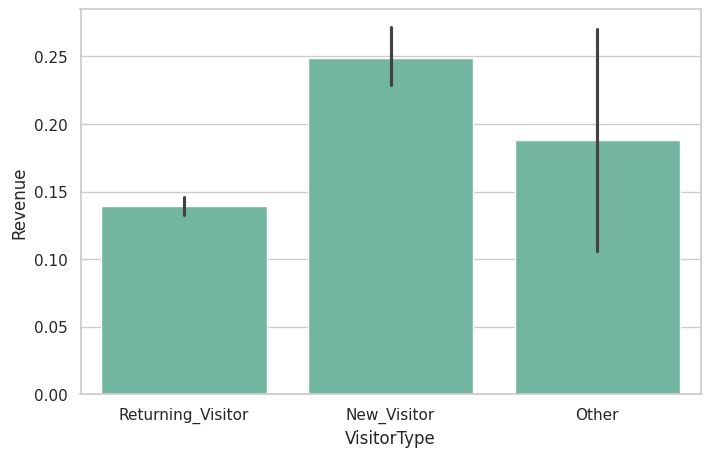

In [19]:
sns.barplot(
    x='VisitorType',
    y='Revenue',
    data=df
)

In [20]:
vt = df.groupby('VisitorType')['Revenue'].agg(sesi='count', transaksi='sum', conv_rate='mean')
vt['persen_sesi'] = vt['sesi'] / vt['sesi'].sum() * 100
vt['persen_transaksi'] = vt['transaksi'] / vt['transaksi'].sum() * 100
vt.round(3)

,sesi,transaksi,conv_rate,persen_sesi,persen_transaksi
VisitorType,,,,,
New_Visitor,1694,422,0.249,13.739,22.117
Other,85,16,0.188,0.689,0.839
Returning_Visitor,10551,1470,0.139,85.572,77.044


Berdasarkan grafik, New_Visitor memiliki conversion rate tertinggi (24,9%) dibandingkan tipe pengunjung lainnya. Sementara itu, Returning_Visitor memiliki conversion rate yang lebih rendah (13,9%), meskipun jumlah pengunjung dengan tipe ini merupakan yang terbanyak pada dataset. Hal ini menunjukkan bahwa pada dataset ini, pengunjung yang kembali ke situs tidak selalu memiliki kemungkinan pembelian yang lebih tinggi dibandingkan pengunjung baru.

Namun jika dilihat dari jumlah transaksi, Returning_Visitor tetap menyumbang paling banyak, yaitu sekitar 77% dari seluruh transaksi, karena jumlah sesinya sangat besar (85,6% dari seluruh sesi). New_Visitor hanya menyumbang sekitar 22% transaksi. Kategori `Other` hanya 85 sesi sehingga terlalu sedikit untuk disimpulkan.

## **Month dengan Revenue**

In [21]:
pd.crosstab(
    df['Month'],
    df['Revenue'],
    normalize='index'
)

Revenue,False,True
Month,,
Aug,0.824480,0.175520
Dec,0.874928,0.125072
Feb,0.983696,0.016304
Jul,0.847222,0.152778
June,0.899306,0.100694
Mar,0.899318,0.100682
May,0.891498,0.108502
Nov,0.746498,0.253502
Oct,0.790528,0.209472


<Axes: xlabel='Month', ylabel='Revenue'>

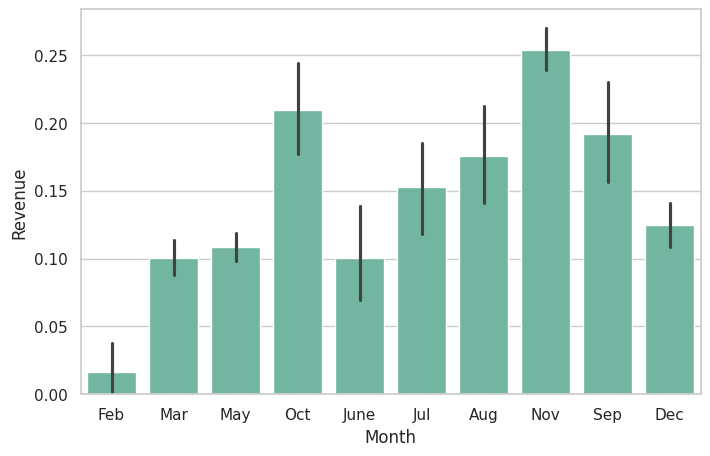

In [22]:
sns.barplot(
    x='Month',
    y='Revenue',
    data=df
)

In [23]:
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
mt = df.groupby('Month')['Revenue'].agg(sesi='count', transaksi='sum', conv_rate='mean').reindex(month_order)
mt['persen_transaksi'] = mt['transaksi'] / mt['transaksi'].sum() * 100
mt.round(3)

,sesi,transaksi,conv_rate,persen_transaksi
Month,,,,
Feb,184,3,0.016,0.157
Mar,1907,192,0.101,10.063
May,3364,365,0.109,19.130
June,288,29,0.101,1.520
Jul,432,66,0.153,3.459
Aug,433,76,0.176,3.983
Sep,448,86,0.192,4.507
Oct,549,115,0.209,6.027
Nov,2998,760,0.254,39.832


Berdasarkan grafik, conversion rate (Revenue) tertinggi terjadi pada bulan **November (25,4%)**, diikuti oleh Oktober (20,9%) dan September (19,2%). November saja menyumbang sekitar 40% dari seluruh transaksi.

Februari memiliki conversion rate terendah (1,6%), sekitar seperenam dari Maret atau Juni (±10%). Namun angka Februari hanya berasal dari 184 sesi dengan 3 transaksi, sehingga mudah berubah dan tidak sebaiknya dibaca sebagai pola yang kuat.

Desember (12,5%) juga jauh di bawah November meskipun jumlah sesinya besar (1.727). Hal ini menunjukkan bahwa tingkat transaksi berbeda pada setiap bulan dalam dataset. Karena Januari dan April tidak ada dalam data, pola sepanjang tahun belum dapat disimpulkan.

## **Weekend dengan Revenue**

In [24]:
pd.crosstab(
    df['Weekend'],
    df['Revenue'],
    normalize='index'
)

Revenue,False,True
Weekend,,
False,0.851089,0.148911
True,0.826011,0.173989


<Axes: xlabel='Weekend', ylabel='Revenue'>

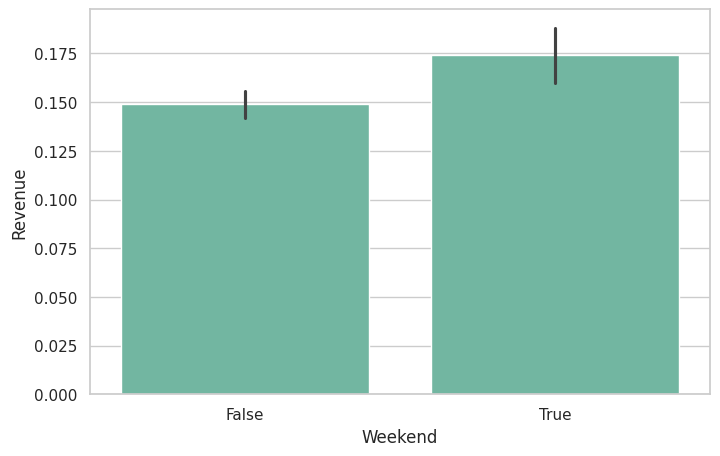

In [25]:
sns.barplot(
    x='Weekend',
    y='Revenue',
    data=df
)

Berdasarkan grafik, conversion rate (Revenue) pada akhir pekan (17,4%) sedikit lebih tinggi dibandingkan hari biasa (14,9%). Selisihnya hanya sekitar 2,5 poin persentase, sehingga weekend bukan pembeda yang kuat antara sesi yang membeli dan tidak.

## **Page Values dengan Revenue**

<Axes: xlabel='Revenue', ylabel='PageValues'>

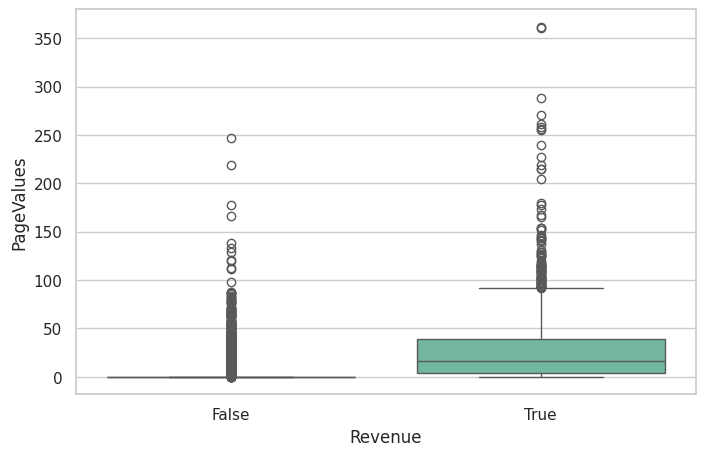

In [26]:
sns.boxplot(
    x='Revenue',
    y='PageValues',
    data=df
)

In [27]:
pv = df.groupby(df['PageValues'] > 0)['Revenue'].agg(sesi='count', transaksi='sum', conv_rate='mean')
pv.index = ['PageValues = 0', 'PageValues > 0']
pv['persen_sesi'] = pv['sesi'] / pv['sesi'].sum() * 100
pv['persen_transaksi'] = pv['transaksi'] / pv['transaksi'].sum() * 100
pv.round(3)

,sesi,transaksi,conv_rate,persen_sesi,persen_transaksi
PageValues = 0,9600,370,0.039,77.859,19.392
PageValues > 0,2730,1538,0.563,22.141,80.608


Berdasarkan grafik, sesi yang menghasilkan transaksi (Revenue = True) memiliki nilai PageValues yang jauh lebih tinggi dibandingkan sesi yang tidak menghasilkan transaksi. Hal ini menunjukkan bahwa semakin tinggi PageValues, semakin besar kemungkinan pengguna melakukan pembelian.

Karena sebagian besar nilai PageValues adalah 0, boxplot kelompok non-pembeli terlihat menempel di bawah. Tabel di atas memisahkan sesi menjadi PageValues = 0 dan PageValues > 0 agar lebih jelas: sesi dengan PageValues = 0 (78% dari seluruh sesi) hanya berkonversi 3,9%, sedangkan sesi dengan PageValues > 0 berkonversi 56,3%. Sekitar 81% pembeli memiliki PageValues > 0. Inilah yang membuat PageValues menjadi sinyal terkuat, sekaligus alasan perlunya kehati-hatian soal *leakage* seperti dicatat pada bagian 1.8.

## **Bounce Rates dengan Revenue**

<Axes: xlabel='Revenue', ylabel='BounceRates'>

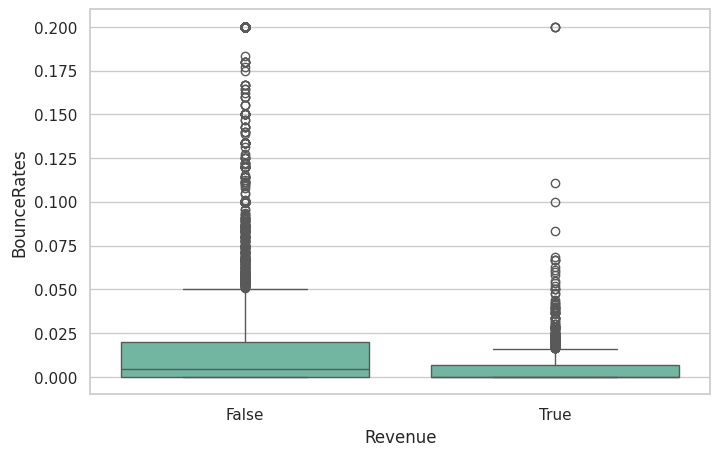

In [28]:
sns.boxplot(
    x='Revenue',
    y='BounceRates',
    data=df
)

Berdasarkan grafik, sesi yang menghasilkan transaksi cenderung memiliki BounceRates yang lebih rendah dibandingkan sesi yang tidak menghasilkan transaksi. Hal ini menunjukkan bahwa pengguna yang langsung meninggalkan situs setelah membuka satu halaman memiliki peluang lebih kecil untuk melakukan pembelian.

## **Exit Rates dengan Revenue**

<Axes: xlabel='Revenue', ylabel='ExitRates'>

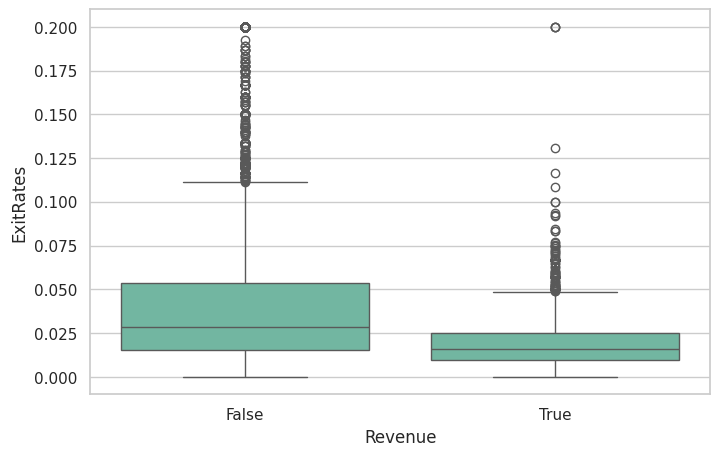

In [29]:
sns.boxplot(
    x='Revenue',
    y='ExitRates',
    data=df
)

Berdasarkan grafik, sesi yang menghasilkan transaksi juga memiliki ExitRates yang lebih rendah dibandingkan sesi yang tidak menghasilkan transaksi. Hal ini menunjukkan bahwa semakin tinggi tingkat pengguna keluar dari halaman, semakin kecil kemungkinan sesi tersebut berakhir dengan transaksi.

## **Halaman Produk dan Durasi dengan Revenue**

Revenue                             False   True 
median    Administrative              0.0     2.0
          Administrative_Duration     0.0    52.4
          Informational               0.0     0.0
          Informational_Duration      0.0     0.0
          ProductRelated             16.0    29.0
          ProductRelated_Duration   510.2  1109.9
rata-rata Administrative              2.1     3.4
          Administrative_Duration    73.7   119.5
          Informational               0.5     0.8
          Informational_Duration     30.2    57.6
          ProductRelated             28.7    48.2
          ProductRelated_Duration  1070.0  1876.2

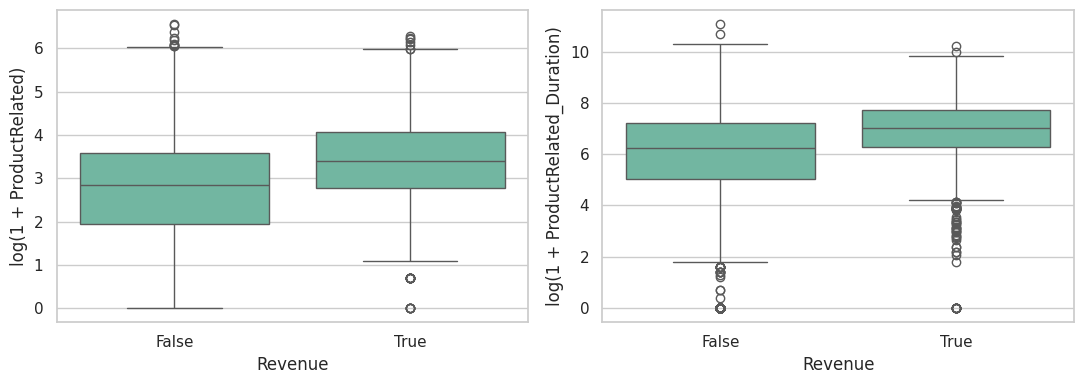

In [30]:
cols_h3 = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
           'ProductRelated', 'ProductRelated_Duration']
display(pd.concat({'median': df.groupby('Revenue')[cols_h3].median(),
                   'rata-rata': df.groupby('Revenue')[cols_h3].mean()}, axis=1).round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['ProductRelated', 'ProductRelated_Duration']):
    sns.boxplot(x='Revenue', y=np.log1p(df[col]), data=df, ax=ax)
    ax.set_ylabel(f'log(1 + {col})')
plt.tight_layout()
plt.show()

Sesi yang menghasilkan transaksi membuka lebih banyak halaman produk (median 29 dibanding 16) dan menghabiskan waktu lebih lama di halaman produk (median ±1.110 detik dibanding ±510 detik). Grafik memakai skala log supaya perbedaan tetap terlihat walaupun datanya miring. Administrative juga lebih tinggi pada pembeli (median 2 dibanding 0), sedangkan durasi Informational bernilai median 0 pada kedua kelompok sehingga kurang membedakan.

Hubungannya terlihat, tetapi tidak sekuat PageValues (korelasi ProductRelated dan durasinya dengan Revenue hanya sekitar 0,15).

# **KESIMPULAN EDA**

## Pengecekan hipotesis

| # | Hipotesis | Hasil | Bukti singkat |
|---|---|---|---|
| H1 | `PageValues` tinggi berkaitan kuat dengan pembelian | **Terdukung (kuat)** | Korelasi 0,49. Konversi 56,3% saat PageValues > 0 dibanding 3,9% saat PageValues = 0 |
| H2 | `ExitRates` dan `BounceRates` rendah berkaitan dengan pembelian | **Terdukung (sedang)** | Korelasi ExitRates -0,21 dan BounceRates -0,15. ExitRates sedikit lebih kuat |
| H3 | Pembeli membuka lebih banyak halaman produk dan durasinya lebih panjang | **Terdukung (sedang)** | Median halaman produk 29 dibanding 16, durasi ±1.110 dibanding ±510 detik. Korelasi sekitar 0,15 |
| H4 | Returning dan new visitor punya conversion rate berbeda | **Terdukung** | New 24,9% dibanding Returning 13,9%. Namun returning menyumbang sekitar 77% transaksi karena jumlah sesinya jauh lebih besar |
| H5 | Conversion rate bervariasi antar bulan | **Terdukung** | 1,6% (Februari) sampai 25,4% (November). Sampel beberapa bulan kecil dan 2 bulan tidak ada |
| H6 | Kode `OperatingSystems`, `Browser`, `Region`, `TrafficType` bersifat nominal | **Diterapkan** | Keempatnya hanya kode, bukan besaran, sehingga diperlakukan sebagai kategori (lihat bagian pemisahan kolom) |
| H7 | `BounceRates` dan `ExitRates` berkorelasi tinggi | **Terdukung** | Korelasi 0,91 (ProductRelated dan durasinya 0,86) |

## Jawaban Important Question
1. **Conversion rate dan ketidakseimbangan:** 15,5% (1.908 dari 12.330 sesi). Perbandingan pembeli dan bukan pembeli sekitar 1 : 5,5, sehingga *accuracy* saja tidak cukup untuk menilai model nanti.
2. **Fitur perilaku terkuat:** PageValues paling kuat, lalu ExitRates (semakin tinggi semakin kecil peluang membeli), kemudian jumlah halaman produk dan durasinya. BounceRates lebih lemah.
3. **Returning vs new dan antar bulan:** keduanya berbeda. New visitor berkonversi lebih tinggi, tetapi returning visitor menyumbang sekitar 77% transaksi. Antar bulan, November paling tinggi (25,4%) dan Februari paling rendah (1,6%, sampel kecil).
4. **Fitur miring dan berkorelasi tinggi:** hampir semua fitur numerik miring ke kanan dan memiliki outlier. Pasangan BounceRates–ExitRates dan ProductRelated–ProductRelated_Duration berkorelasi tinggi sehingga berisiko menimbulkan multikolinearitas pada model seperti Logistic Regression.

## Insight utama
1. Hanya 15,5% sesi yang berakhir transaksi.
2. PageValues adalah sinyal terkuat: 81% pembeli punya PageValues > 0, sedangkan sesi ber-PageValues 0 hampir tidak pernah membeli (3,9%).
3. Sesi pembeli cenderung memiliki ExitRates dan BounceRates yang lebih rendah, dan ExitRates sedikit lebih kuat.
4. Pembeli membuka lebih banyak halaman produk (median 29 dibanding 16) dan lebih lama di halaman tersebut, tetapi hubungannya hanya sedang.
5. Konversi tinggi pada kuartal akhir (September sampai November), terutama November yang menyumbang sekitar 40% transaksi.
6. New visitor lebih efisien per sesi, tetapi returning visitor adalah penyumbang transaksi terbesar.
7. Weekend hampir tidak membedakan sesi pembeli (17,4% dibanding 14,9%).

## Saran awal untuk bisnis
- Perhatikan sesi yang sudah menunjukkan tanda kuat (PageValues > 0, exit rate rendah, banyak membuka halaman produk) tetapi belum membeli, karena peluang konversinya paling tinggi.
- Fokuskan marketing dan *retargeting* menjelang dan selama kuartal akhir.
- Tetap prioritaskan returning visitor karena jumlah transaksinya paling besar, sambil mempertahankan kampanye untuk pengunjung baru yang konversinya lebih tinggi.
- Periksa halaman yang membuat pengunjung sering keluar (exit rate tinggi) sebagai bahan perbaikan desain situs.

## Catatan untuk tahap berikutnya
- Putuskan penanganan duplikat dan outlier (lihat bagian masing-masing).
- Ubah fitur kategorikal (termasuk kode OperatingSystems, Browser, Region, TrafficType) menjadi bentuk yang bisa dibaca model, dan pertimbangkan transformasi untuk fitur yang miring.
- Untuk pasangan fitur yang berkorelasi tinggi, pertimbangkan memakai salah satunya pada model seperti Logistic Regression.
- Cek apakah `PageValues` benar-benar tersedia saat keputusan dibuat (risiko *leakage*), dan pertimbangkan membandingkan model dengan dan tanpa fitur ini.
- Bagi data latih dan data uji dengan menjaga proporsi pembeli tetap sama, serta menilai model tidak hanya dengan *accuracy*.

## Keterbatasan
- Data hanya mencakup 10 bulan dan beberapa kategori memiliki sesi sedikit (Februari, `Other`).
- Hasil EDA menunjukkan keterkaitan, bukan sebab-akibat.
- Tidak ada identitas pengguna, sehingga satu pengguna bisa muncul di banyak sesi.